In [ ]:
# Deep Learning NLP Text Classifier

## IMDB Movie Review Sentiment Analysis

**Technology:** Python, TensorFlow/Keras, Scikit-learn  
**Technique:** TF-IDF + Deep Neural Network  
**Dataset:** IMDB Movie Reviews  
**Task:** Binary Sentiment Classification

In [1]:
import numpy as np

print("NumPy version:", np.__version__)
print("NumPy location:", np.__file__)

NumPy version: 2.2.6
NumPy location: C:\Users\msaip\AppData\Roaming\Python\Python312\site-packages\numpy\__init__.py


In [3]:
import numpy as np

print("NumPy version:", np.__version__)
print("NumPy location:", np.__file__)

NumPy version: 2.2.6
NumPy location: C:\Users\msaip\AppData\Roaming\Python\Python312\site-packages\numpy\__init__.py


In [5]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import imdb

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.20.0
NumPy version: 2.2.6
Libraries imported successfully!


In [8]:
vocab_size = 10000

(X_train_raw, y_train), (X_test_raw, y_test) = imdb.load_data(
    num_words=vocab_size
)

print("Training samples:", len(X_train_raw))
print("Testing samples:", len(X_test_raw))

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 7s 0us/step
Training samples: 25000
Testing samples: 25000


In [9]:
word_index = imdb.get_word_index()

reverse_word_index = {
    value: key for key, value in word_index.items()
}

def decode_review(review):
    return " ".join(
        reverse_word_index.get(i - 3, "?")
        for i in review
        if i >= 3
    )

train_text = [decode_review(review) for review in X_train_raw]
test_text = [decode_review(review) for review in X_test_raw]

print("Sample review:")
print(train_text[0][:1000])

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Sample review:
this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert is an amazing actor and now the same being director father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also to the two little boy's that played the of norman and paul they were just brilliant children are often left out of the list i think because the stars that play them all grown up are such a big profile for the whole film but these children are amazing and shoul

In [10]:
vectorizer = TfidfVectorizer(
    max_features=10000,
    stop_words="english",
    ngram_range=(1, 2),
    sublinear_tf=True,
    min_df=2,
    max_df=0.95
)

X_train_tfidf = vectorizer.fit_transform(train_text)
X_test_tfidf = vectorizer.transform(test_text)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (25000, 10000)
Testing TF-IDF shape: (25000, 10000)


In [11]:
X_train, X_val, y_train_final, y_val = train_test_split(
    X_train_tfidf,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Test data:", X_test_tfidf.shape)

Training data: (20000, 10000)
Validation data: (5000, 10000)
Test data: (25000, 10000)


In [12]:
X_train = X_train.toarray()
X_val = X_val.toarray()
X_test = X_test_tfidf.toarray()

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)

Training shape: (20000, 10000)
Validation shape: (5000, 10000)
Test shape: (25000, 10000)


In [13]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization

model = Sequential([
    Dense(512, activation="relu", input_shape=(10000,)),
    BatchNormalization(),
    Dropout(0.50),

    Dense(256, activation="relu"),
    BatchNormalization(),
    Dropout(0.40),

    Dense(128, activation="relu"),
    BatchNormalization(),
    Dropout(0.30),

    Dense(64, activation="relu"),
    Dropout(0.20),

    Dense(1, activation="sigmoid")
])

model.summary()

C:\Users\msaip\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │     5,120,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,296,641 (20.21 MB)

 Trainable params: 5,294,849 (20.20 MB)

 Non-trainable params: 1,792 (7.00 KB)

In [14]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [15]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

print("Callbacks created successfully!")

Callbacks created successfully!


In [16]:
history = model.fit(
    X_train,
    y_train_final,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=128,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/20
157/157 ━━━━━━━━━━━━━━━━━━━━ 23s 117ms/step - accuracy: 0.7907 - loss: 0.4415 - val_accuracy: 0.8288 - val_loss: 0.6023 - learning_rate: 0.0010
Epoch 2/20
157/157 ━━━━━━━━━━━━━━━━━━━━ 17s 105ms/step - accuracy: 0.9187 - loss: 0.2069 - val_accuracy: 0.8150 - val_loss: 0.4447 - learning_rate: 0.0010
Epoch 3/20
157/157 ━━━━━━━━━━━━━━━━━━━━ 16s 100ms/step - accuracy: 0.9503 - loss: 0.1303 - val_accuracy: 0.8604 - val_loss: 0.3356 - learning_rate: 0.0010
Epoch 4/20
157/157 ━━━━━━━━━━━━━━━━━━━━ 18s 116ms/step - accuracy: 0.9733 - loss: 0.0753 - val_accuracy: 0.8678 - val_loss: 0.4422 - learning_rate: 0.0010
Epoch 5/20
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - accuracy: 0.9829 - loss: 0.0488
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
157/157 ━━━━━━━━━━━━━━━━━━━━ 19s 117ms/step - accuracy: 0.9829 - loss: 0.0488 - val_accuracy: 0.8630 - val_loss: 0.5985 - learning_rate: 0.0010
Epoch 6/20
157/157 ━━━━━━━━━━━━━━━━━━━━ 16s 103ms/step - accuracy: 0.990

In [17]:
best_val_accuracy = max(history.history["val_accuracy"])

print(
    "Best Validation Accuracy:",
    round(best_val_accuracy * 100, 2),
    "%"
)

Best Validation Accuracy: 86.86 %


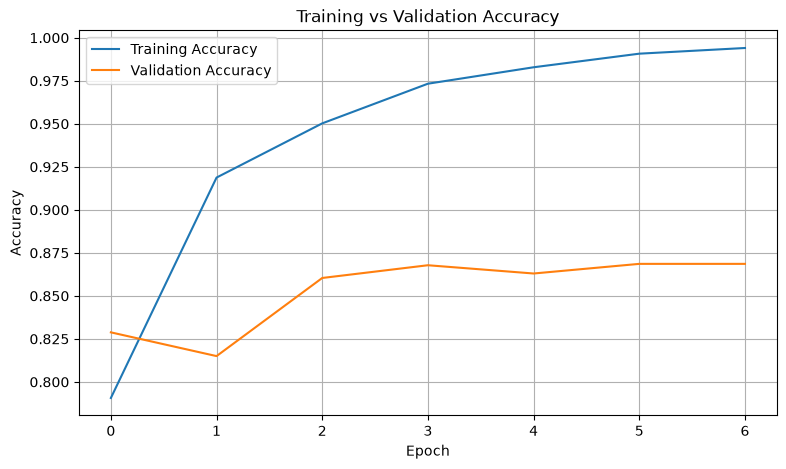

In [18]:
plt.figure(figsize=(9, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

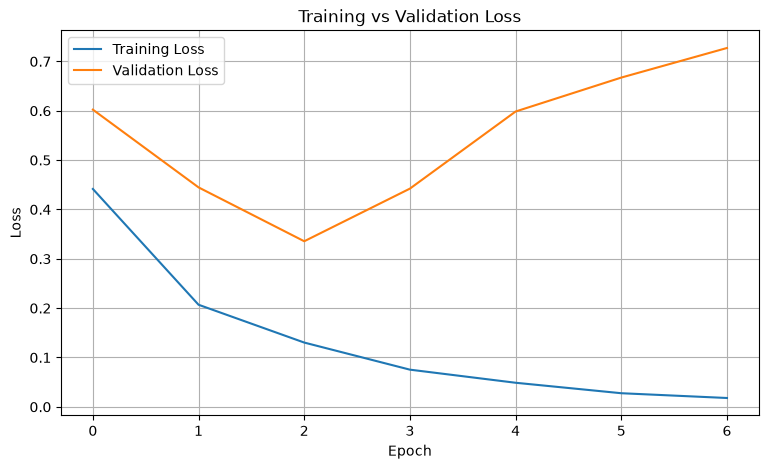

In [19]:
plt.figure(figsize=(9, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [20]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

Test Loss: 0.3753
Test Accuracy: 84.35 %


In [21]:
y_probability = model.predict(
    X_test,
    batch_size=128,
    verbose=0
)

y_pred = (y_probability >= 0.5).astype(int).flatten()

print("Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Negative", "Positive"]
    )
)

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Classification Report:
              precision    recall  f1-score   support

    Negative       0.80      0.92      0.86     12500
    Positive       0.91      0.76      0.83     12500

    accuracy                           0.84     25000
   macro avg       0.85      0.84      0.84     25000
weighted avg       0.85      0.84      0.84     25000

Confusion Matrix:
[[11554   946]
 [ 2966  9534]]


In [22]:
sample_reviews = [
    "This movie was absolutely fantastic and I loved every moment of it.",
    "The movie was boring, slow and extremely disappointing.",
    "Amazing acting, excellent story and wonderful direction.",
    "I hated this movie. It was terrible and a complete waste of time.",
    "One of the best movies I have ever watched."
]

sample_tfidf = vectorizer.transform(sample_reviews).toarray()

sample_predictions = model.predict(
    sample_tfidf,
    verbose=0
)

for review, prediction in zip(sample_reviews, sample_predictions):
    probability = float(prediction[0])

    if probability >= 0.5:
        sentiment = "Positive"
        confidence = probability
    else:
        sentiment = "Negative"
        confidence = 1 - probability

    print("Review:", review)
    print("Prediction:", sentiment)
    print("Confidence:", round(confidence * 100, 2), "%")
    print("-" * 80)

Review: This movie was absolutely fantastic and I loved every moment of it.
Prediction: Positive
Confidence: 60.37 %
--------------------------------------------------------------------------------
Review: The movie was boring, slow and extremely disappointing.
Prediction: Negative
Confidence: 99.92 %
--------------------------------------------------------------------------------
Review: Amazing acting, excellent story and wonderful direction.
Prediction: Positive
Confidence: 99.62 %
--------------------------------------------------------------------------------
Review: I hated this movie. It was terrible and a complete waste of time.
Prediction: Negative
Confidence: 99.81 %
--------------------------------------------------------------------------------
Review: One of the best movies I have ever watched.
Prediction: Positive
Confidence: 91.26 %
--------------------------------------------------------------------------------


In [23]:
import joblib

model.save("sentiment_classifier.keras")
joblib.dump(vectorizer, "tfidf_vectorizer.pkl")

print("Model saved as: sentiment_classifier.keras")
print("TF-IDF vectorizer saved as: tfidf_vectorizer.pkl")

Model saved as: sentiment_classifier.keras
TF-IDF vectorizer saved as: tfidf_vectorizer.pkl


In [24]:
print("===== FINAL MODEL PERFORMANCE =====")
print("Best Validation Accuracy:", round(best_val_accuracy * 100, 2), "%")
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Test Loss:", round(test_loss, 4))

===== FINAL MODEL PERFORMANCE =====
Best Validation Accuracy: 86.86 %
Test Accuracy: 84.35 %
Test Loss: 0.3753


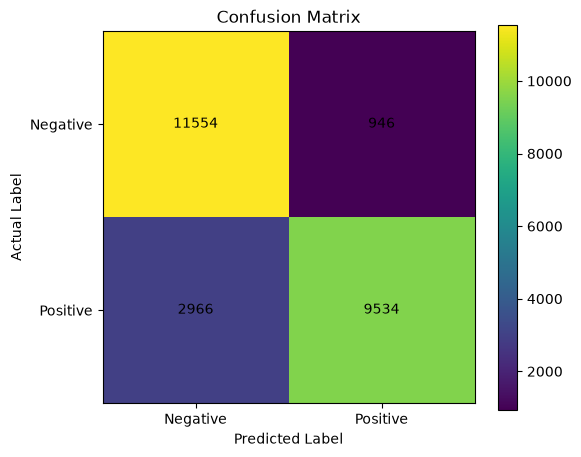

In [25]:
plt.figure(figsize=(6, 5))

plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks([0, 1], ["Negative", "Positive"])
plt.yticks([0, 1], ["Negative", "Positive"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.show()

In [26]:
results = []

for review, prediction in zip(sample_reviews, sample_predictions):
    probability = float(prediction[0])

    if probability >= 0.5:
        sentiment = "Positive"
        confidence = probability
    else:
        sentiment = "Negative"
        confidence = 1 - probability

    results.append({
        "Review": review,
        "Prediction": sentiment,
        "Confidence (%)": round(confidence * 100, 2)
    })

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

                                                             Review Prediction  Confidence (%)
This movie was absolutely fantastic and I loved every moment of it.   Positive           60.37
            The movie was boring, slow and extremely disappointing.   Negative           99.92
           Amazing acting, excellent story and wonderful direction.   Positive           99.62
  I hated this movie. It was terrible and a complete waste of time.   Negative           99.81
                        One of the best movies I have ever watched.   Positive           91.26


In [27]:
import os

print("Saved files:")

for file in ["sentiment_classifier.keras", "tfidf_vectorizer.pkl"]:
    if os.path.exists(file):
        print("✓", file)
    else:
        print("✗", file)

Saved files:
✓ sentiment_classifier.keras
✓ tfidf_vectorizer.pkl


In [28]:
## Conclusion

This project developed an NLP-based sentiment classification system using the IMDB movie review dataset. The text data was converted into numerical features using TF-IDF and classified using a multi-layer neural network built with TensorFlow/Keras.

The neural network uses Batch Normalization and Dropout to improve training stability and reduce overfitting. Early Stopping and learning-rate reduction were also used during training.

The model was evaluated using validation accuracy, test accuracy, precision, recall, F1-score, confusion matrix, and sample predictions with confidence scores.

The trained model and TF-IDF vectorizer were saved for future use.

SyntaxError: invalid syntax (3809213138.py, line 3)